# Vanguard: análisis del experimento A/B

**Autores: Salvador Cruz de Bustos y Walnert Padron**

## Objetivo y organización

Comparamos el diseño nuevo (Test) con el antiguo (Control) para comprobar si mejora la finalización del proceso y cómo cambia la experiencia de uso.

Este notebook reúne el trabajo de ambos: exploración de perfiles, preparación de actividad web, métricas, contrastes y evaluación. Utilizamos una preparación común para evitar que distintos criterios de limpieza produzcan resultados incompatibles.

1. Exploración de perfiles y asignación de los grupos.
2. Limpieza y reconstrucción de los recorridos web.
3. Finalización, tiempos, retrocesos y análisis por segmentos.
4. Contrastes de finalización, umbral relativo, edad y antigüedad.
5. Evaluación y conclusiones conjuntas.

Los cuatro archivos originales se leen desde `data/`. Para reproducir el análisis, ejecutamos las celdas en orden desde el principio. No modificamos los archivos originales.

**Unidades de análisis:** los perfiles y la finalización se calculan por cliente; las visitas se identifican con cliente y visita; los tiempos y retrocesos se calculan sobre intervalos y transiciones evaluables. Una tasa por transición no equivale a una tasa por cliente.

## 1. Carga de los datos

Importamos pandas y cargamos el archivo de perfiles en `df_demo`.

Aunque el archivo tiene extensión `.txt`, sus datos están separados por comas, por lo que puedo leerlo con `pd.read_csv()`.

Mostramos las primeras cinco filas con `.head()` para comprobar la carga y reconocer las columnas.

In [1]:
import pandas as pd

In [2]:
df_demo = pd.read_csv("data/df_final_demo.txt")

df_demo.head()

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0


## 2. Estructura y datos disponibles

Utilizamos `.info()` para comprobar el número de filas y columnas, los tipos de datos y cuántos valores no nulos hay en cada columna.

In [3]:
df_demo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70609 entries, 0 to 70608
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   client_id         70609 non-null  int64  
 1   clnt_tenure_yr    70595 non-null  float64
 2   clnt_tenure_mnth  70595 non-null  float64
 3   clnt_age          70594 non-null  float64
 4   gendr             70595 non-null  object 
 5   num_accts         70595 non-null  float64
 6   bal               70595 non-null  float64
 7   calls_6_mnth      70595 non-null  float64
 8   logons_6_mnth     70595 non-null  float64
dtypes: float64(7), int64(1), object(1)
memory usage: 4.8+ MB


El archivo contiene **70.609 filas y 9 columnas**.

- `client_id` no tiene valores nulos.
- `clnt_age` tiene 15 valores nulos.
- Las otras siete columnas tienen 14 valores nulos cada una.

A continuación revisamos las filas afectadas para comprobar si los datos ausentes corresponden a los mismos clientes.

## 3. Revisión de valores nulos

Seleccionamos las filas que tienen al menos un dato ausente.

`.isna()` identifica los nulos y `.any(axis=1)` comprueba si hay alguno en cada fila.

In [4]:
df_demo[df_demo.isna().any(axis=1)]

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
4164,7402828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8316,355337,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8677,8412164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9583,4666211,8.0,106.0,NaN,F,2.0,42550.55,4.0,7.0
13444,2222915,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18066,4876926,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25961,5277910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28432,7616759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35323,8191345,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43518,1227228,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Hemos encontrado **15 clientes con algún dato ausente**:

- 14 solo tienen el identificador `client_id`; el resto de su perfil está vacío.
- El cliente `4666211` únicamente tiene la edad vacía.

**Decisión provisional:** conservar estos registros y no rellenar los datos ausentes. Aunque les falte información de perfil, podrían tener actividad web y una asignación al experimento.

En los análisis de edad, saldo u otras características, tendré en cuenta cuántos clientes tienen información disponible.

## 4. Comprobación de clientes duplicados

Comprobamos si algún `client_id` aparece más de una vez, ya que este archivo debería contener una única fila por cliente.

In [5]:
df_demo['client_id'].duplicated().sum()

np.int64(0)

No hay identificadores duplicados. Como tampoco hay identificadores nulos, el archivo contiene **70.609 clientes únicos**, con una fila por cliente.

## 5. Resumen de las variables numéricas

Utilizamos `.describe()` para revisar medias, medianas, cuartiles y valores mínimos y máximos.

Esta primera revisión ayuda a conocer los datos y a detectar valores que debamos investigar. Los cálculos excluyen los valores nulos de cada columna.

Aunque aparece en el resumen, no interpretamos las estadísticas de `client_id`, porque es un identificador.

In [6]:
df_demo.describe()

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,num_accts,bal,calls_6_mnth,logons_6_mnth
count,7.060900e+04,70595.000000,70595.000000,70594.000000,70595.000000,7.059500e+04,70595.000000,70595.000000
mean,5.004992e+06,12.052950,150.659367,46.442240,2.255528,1.474452e+05,3.382478,5.566740
std,2.877278e+06,6.871819,82.089854,15.591273,0.534997,3.015087e+05,2.236580,2.353286
min,1.690000e+02,2.000000,33.000000,13.500000,1.000000,1.378942e+04,0.000000,1.000000
25%,2.519329e+06,6.000000,82.000000,32.500000,2.000000,3.734683e+04,1.000000,4.000000
50%,5.016978e+06,11.000000,136.000000,47.000000,2.000000,6.333290e+04,3.000000,5.000000
75%,7.483085e+06,16.000000,192.000000,59.000000,2.000000,1.375449e+05,6.000000,7.000000
max,9.999839e+06,62.000000,749.000000,96.000000,8.000000,1.632004e+07,7.000000,9.000000


## 6. Revisión de la variable de género

Comprobamos qué códigos aparecen en `gendr` y cuántos clientes hay en cada uno, incluyendo los valores nulos.

Antes de cambiar sus etiquetas, revisaremos su significado para no interpretar incorrectamente los códigos.

In [7]:
df_demo['gendr'].value_counts(dropna=False)

gendr
U      24122
M      23724
F      22746
NaN       14
X          3
Name: count, dtype: int64

### Resultado de la revisión de género

Los valores registrados son:

- `U`: 24.122 clientes.
- `M`: 23.724 clientes.
- `F`: 22.746 clientes.
- `X`: 3 clientes.
- Nulos: 14 clientes.

El diccionario facilitado indica que esta columna representa el género, pero no detalla el significado de cada código.

Por ahora conservamos los códigos originales. No sustituimos `U` ni `X` por valores nulos, ni eliminamos sus registros. Queda pendiente confirmar su significado.

## 7. Revisión de edades y antigüedad

Hay 374 clientes con una edad registrada inferior a 18 años. No los eliminamos automáticamente por ser menores.

En las primeras filas aparecen casos cuya antigüedad supera su edad. Esto plantea una posible incoherencia entre ambas variables que necesita revisión.

Vamos a comprobar cuántos casos presentan esta situación en todo el archivo, no solo entre los menores. Por ahora conservamos los datos originales.

In [8]:
menores = df_demo.loc[df_demo['clnt_age'] < 18,['client_id', 'clnt_age', 'clnt_tenure_yr', 'clnt_tenure_mnth']]

print("Clientes menores de 18 años:", len(menores))
menores.head(10)

Clientes menores de 18 años: 374


,client_id,clnt_age,clnt_tenure_yr,clnt_tenure_mnth
768,5249795,17.5,17.0,208.0
1194,4286237,17.5,21.0,257.0
2283,5269888,17.5,20.0,243.0
2716,6516140,17.5,5.0,66.0
2846,5114008,17.5,4.0,57.0
3195,5747508,17.5,5.0,66.0
3581,3322887,17.5,18.0,216.0
3584,2064675,17.5,5.0,68.0
4218,5624999,17.5,23.0,283.0
4712,9691201,17.5,5.0,66.0


In [9]:
antiguedad_superior_edad = df_demo.loc[df_demo['clnt_tenure_mnth'] > df_demo['clnt_age'] * 12,['client_id', 'clnt_age', 'clnt_tenure_yr', 'clnt_tenure_mnth']]

print("Clientes con antigüedad superior a su edad:",len(antiguedad_superior_edad))

antiguedad_superior_edad.head(10)

Clientes con antigüedad superior a su edad: 634


,client_id,clnt_age,clnt_tenure_yr,clnt_tenure_mnth
108,7449147,26.5,27.0,330.0
354,8257047,24.5,24.0,297.0
508,5870441,25.5,25.0,310.0
720,4529371,24.5,24.0,296.0
846,4267612,28.0,28.0,345.0
920,1194237,30.5,30.0,370.0
970,4955883,26.0,29.0,349.0
1138,1330615,18.5,23.0,285.0
1194,4286237,17.5,21.0,257.0
1286,1225744,25.5,26.0,321.0


### Criterio común de calidad

Conservamos los perfiles originales. Los casos cuya antigüedad supera su edad se revisan mediante análisis de sensibilidad; no corregimos sus valores sin información adicional.

## 8. Revisión de la asignación al experimento

Cargo el archivo que indica qué versión de la interfaz tiene asignada cada cliente.

Vamos a comprobar su estructura, los valores de `Variation` y si existen identificadores duplicados o asignaciones ausentes.

In [10]:
df_experiment = pd.read_csv("data/df_final_experiment_clients.txt")

df_experiment.head()

,client_id,Variation
0,9988021,Test
1,8320017,Test
2,4033851,Control
3,1982004,Test
4,9294070,Control


In [11]:
df_experiment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70609 entries, 0 to 70608
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   client_id  70609 non-null  int64 
 1   Variation  50500 non-null  object
dtypes: int64(1), object(1)
memory usage: 1.1+ MB


In [12]:
print(df_experiment['Variation'].value_counts(dropna=False))

print("Identificadores duplicados:",df_experiment['client_id'].duplicated().sum())

Variation
Test       26968
Control    23532
NaN        20109
Name: count, dtype: int64
Identificadores duplicados: 0


### Resultado de la revisión de grupos

El archivo contiene 70.609 clientes únicos: 26.968 asignados a Test, 23.532 a Control y 20.109 sin grupo informado.

No hay identificadores duplicados ni otros valores de grupo.

Conservamos los registros sin asignación, sin rellenarlos como Test o Control. Su tratamiento se acordará antes de definir la población del análisis.

## 9. Unión de perfiles y asignación al experimento

Hemos comprobado que ambos archivos contienen los mismos clientes y que cada identificador aparece una sola vez en cada archivo.

Los unimos mediante `client_id` para tener el perfil y el grupo asignado en una misma tabla. Conservamos también los clientes sin grupo informado y los perfiles con datos ausentes.

In [13]:
print("Clientes de perfiles que no aparecen en asignación:",(~df_demo['client_id'].isin(df_experiment['client_id'])).sum())

print("Clientes de asignación que no aparecen en perfiles:",(~df_experiment['client_id'].isin(df_demo['client_id'])).sum())

Clientes de perfiles que no aparecen en asignación: 0
Clientes de asignación que no aparecen en perfiles: 0


In [14]:
df_clientes = df_demo.merge(df_experiment,on='client_id',how='left',validate='one_to_one')

print("Filas y columnas:", df_clientes.shape)
df_clientes.head()

Filas y columnas: (70609, 10)


,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,Variation
0,836976,6.0,73.0,60.5,U,2.0,45105.30,6.0,9.0,Test
1,2304905,7.0,94.0,58.0,U,2.0,110860.30,6.0,9.0,Control
2,1439522,5.0,64.0,32.0,U,2.0,52467.79,6.0,9.0,Test
3,1562045,16.0,198.0,49.0,M,2.0,67454.65,3.0,6.0,Test
4,5126305,12.0,145.0,33.0,F,2.0,103671.75,0.0,3.0,Control


### Población del experimento

Para comparar las interfaces utilizamos únicamente los clientes con asignación Test o Control. Los registros sin asignación se conservan en la tabla original, pero no entran en las métricas del experimento.

## 10. Distribución del saldo de los clientes

La media del saldo es bastante superior a la mediana. Representamos su distribución para observar la concentración de los valores y los posibles extremos.

Este análisis incluye todos los perfiles con saldo disponible, tengan o no grupo asignado. No eliminamos los saldos elevados automáticamente.

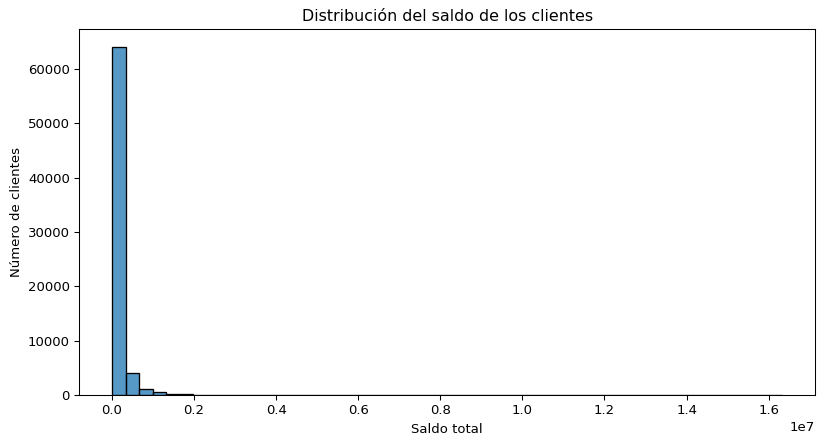

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(data=df_clientes, x='bal', bins=50)

plt.title("Distribución del saldo de los clientes")
plt.xlabel("Saldo total")
plt.ylabel("Número de clientes")
plt.show()

Percentil 95 del saldo: 524823.6630000005


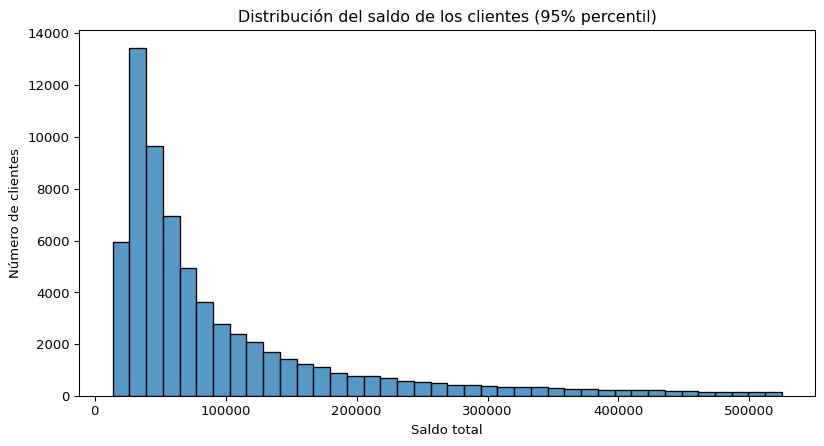

In [16]:
limite_saldo = df_clientes['bal'].quantile(0.95)

plt.figure(figsize=(10, 5))
sns.histplot(data=df_clientes[df_clientes['bal'] <= limite_saldo], x='bal', bins=40)

plt.title("Distribución del saldo de los clientes (95% percentil)")
plt.xlabel("Saldo total")
plt.ylabel("Número de clientes")
plt.show()

print("Percentil 95 del saldo:", limite_saldo)

### Interpretación del saldo

El percentil 95 del saldo es de **524.823,66**. Aproximadamente el 95 % de los clientes con saldo disponible tiene un valor igual o inferior a esa cantidad.

Al limitar la visualización a ese intervalo, observamos que los saldos más frecuentes están por debajo de 100.000 y que la frecuencia disminuye a medida que aumenta el saldo.

La mediana de **63.332,90** describe mejor el centro de esta distribución que la media de **147.445,24**, que está influida por los saldos elevados.

El 5 % superior se ha omitido únicamente de este segundo gráfico. Todos los registros permanecen en `df_clientes`. Estas observaciones corresponden al archivo completo de perfiles, no exclusivamente a Test y Control.

## 11. Selección de clientes y comparación de los grupos

Como criterio común del equipo, analizaremos los clientes con asignación Test o Control. Los 20.109 clientes sin grupo informado quedan fuera de esta comparación, pero se conservan en la tabla original.

Compararemos los porcentajes de género y de intervalos de edad dentro de cada grupo.

Los casos cuya antigüedad supera su edad se mantienen por ahora. En el análisis de edad comprobaremos si las conclusiones cambian al excluirlos, sin modificar sus valores.

In [17]:
df_experimento = df_clientes.loc[df_clientes['Variation'].isin(['Test', 'Control'])].copy()

print("Clientes con grupo asignado:", len(df_experimento))

Clientes con grupo asignado: 50500


In [18]:
porcentaje_genero = pd.crosstab(df_experimento['Variation'],df_experimento['gendr'].fillna('Sin dato'),normalize='index') * 100

porcentaje_genero.round(2)

gendr,F,M,Sin dato,U,X
Variation,,,,,
Control,32.05,33.87,0.02,34.06,0.00
Test,32.32,33.29,0.03,34.36,0.01


### Comparación de género entre Test y Control

Los porcentajes de los códigos de género son similares en ambos grupos:

- `F`: 32,05 % en Control y 32,32 % en Test.
- `M`: 33,87 % en Control y 33,29 % en Test.
- `U`: 34,06 % en Control y 34,36 % en Test.

Los valores nulos y el código `X` representan porcentajes muy pequeños. Un porcentaje mostrado como 0,00 % puede deberse al redondeo y no implica necesariamente que no haya registros.

No observamos grandes diferencias en la composición por género. Esta comparación es descriptiva y no demuestra por sí sola que la asignación de los grupos fuera aleatoria.

Conservamos los códigos originales porque su significado no está detallado en el diccionario facilitado.

In [19]:
# Crear los mismos intervalos para ambos grupos
limites = [0, 18, 30, 40, 50, 60, 70, float('inf')]
etiquetas = [
    'Menores de 18',
    '18 a menos de 30',
    '30 a menos de 40',
    '40 a menos de 50',
    '50 a menos de 60',
    '60 a menos de 70',
    '70 o más'
]

df_experimento['grupo_edad'] = pd.cut(
    df_experimento['clnt_age'],
    bins=limites,
    labels=etiquetas,
    right=False
)

# Incluir las edades ausentes como una categoría
df_experimento['grupo_edad'] = (
    df_experimento['grupo_edad']
    .cat.add_categories('Sin dato')
    .fillna('Sin dato')
)

# Porcentajes dentro de cada grupo
porcentaje_edad = pd.crosstab(
    df_experimento['Variation'],
    df_experimento['grupo_edad'],
    normalize='index'
) * 100

porcentaje_edad.round(2)

grupo_edad,Menores de 18,18 a menos de 30,30 a menos de 40,40 a menos de 50,50 a menos de 60,60 a menos de 70,70 o más,Sin dato
Variation,,,,,,,,
Control,0.12,16.60,18.77,17.11,22.13,18.29,6.95,0.03
Test,0.13,16.92,19.49,17.21,21.69,17.88,6.66,0.03


### Resultado de la comparación por edad

El intervalo más frecuente es el de 50 a menos de 60 años: representa el 22,13 % de Control y el 21,69 % de Test.

Las distribuciones son similares. Ningún intervalo presenta una diferencia superior a un punto porcentual entre grupos.

Esta primera comparación incluye las edades registradas, también en los casos cuya antigüedad supera su edad. A continuación compruebo si excluir estos casos cambia las conclusiones.

In [20]:
# Identificar los casos cuya antigüedad supera la edad
casos_dudosos = (df_experimento['clnt_tenure_mnth'] >df_experimento['clnt_age'] * 12)

print("Casos dudosos por grupo:")
print(df_experimento.loc[casos_dudosos, 'Variation'].value_counts())

# Recalcular los porcentajes excluyendo únicamente esos casos
porcentaje_edad_sin_dudosos = pd.crosstab(
    df_experimento.loc[~casos_dudosos, 'Variation'],
    df_experimento.loc[~casos_dudosos, 'grupo_edad'],
    normalize='index'
) * 100

porcentaje_edad_sin_dudosos.round(2)

Casos dudosos por grupo:
Variation
Test       208
Control    163
Name: count, dtype: int64


grupo_edad,Menores de 18,18 a menos de 30,30 a menos de 40,40 a menos de 50,50 a menos de 60,60 a menos de 70,70 o más,Sin dato
Variation,,,,,,,,
Control,0.10,16.08,18.87,17.22,22.29,18.42,7.00,0.03
Test,0.11,16.37,19.60,17.31,21.86,18.02,6.71,0.03


### Comprobación del efecto de los casos dudosos

De los 634 casos detectados en el archivo completo, 371 tienen grupo asignado: 208 en Test y 163 en Control.

Al repetir la comparación sin estos casos:

- El intervalo más frecuente sigue siendo de 50 a menos de 60 años.
- Las diferencias entre Test y Control siguen siendo inferiores a un punto porcentual en todos los intervalos.
- El porcentaje de clientes de 18 a menos de 30 años baja ligeramente en ambos grupos.

Por tanto, excluir estos registros no cambia la conclusión descriptiva: ambos grupos presentan una composición por edad similar.

Conservamos los registros originales. Esta comprobación no confirma que las edades sean correctas, sino que los casos identificados no alteran la conclusión general de esta comparación.

## 12. Antigüedad de los clientes en Vanguard

Comparamos la antigüedad de los clientes de Test y Control para conocer cuánto tiempo llevan en la empresa.

Utilizamos la antigüedad expresada en años. Primero analizo los valores registrados y después comprobaremos el efecto de los casos cuya antigüedad supera la edad.

In [21]:
resumen_antiguedad = (
    df_experimento.groupby('Variation')['clnt_tenure_yr']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

resumen_antiguedad.round(2)

,count,mean,median,min,max
Variation,,,,,
Control,23527,12.09,11.0,2.0,55.0
Test,26961,11.98,11.0,2.0,55.0


### Resultado de la comparación de antigüedad

Ambos grupos presentan una mediana de 11 años de antigüedad. Las medias también son similares: 12,09 años en Control y 11,98 en Test.

Estos valores indican que el cliente típico de ambos grupos mantiene una relación de varios años con Vanguard.

Hay información de antigüedad para 23.527 clientes de Control y 26.961 de Test. Quedan fuera de estos cálculos 5 y 7 clientes, respectivamente, por tener el dato ausente.

In [22]:
resumen_antiguedad_sin_dudosos = (
    df_experimento.loc[~casos_dudosos]
    .groupby('Variation')['clnt_tenure_yr']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

resumen_antiguedad_sin_dudosos.round(2)

,count,mean,median,min,max
Variation,,,,,
Control,23364,11.99,11.0,2.0,55.0
Test,26753,11.87,11.0,2.0,55.0


### Antigüedad al excluir los casos dudosos

Al excluir los clientes cuya antigüedad supera su edad:

- La media de Control pasa de 12,09 a 11,99 años.
- La media de Test pasa de 11,98 a 11,87 años.
- La mediana permanece en 11 años en ambos grupos.

La exclusión apenas modifica el resumen y no cambia la conclusión: Test y Control presentan una antigüedad similar.

Los registros se conservan en la tabla principal del experimento. Esta exclusión se ha utilizado únicamente como comprobación de sensibilidad del análisis de antigüedad.

## 13. Saldo y actividad previa por grupo

Comparamos el saldo, el número de cuentas, las llamadas y los accesos de los últimos seis meses entre Test y Control.

Utilizamos la media y la mediana para resumir cada variable. En el saldo prestaremos especial atención a la mediana, porque los valores elevados influyen en la media.

Mantenemos todos los clientes con grupo asignado. Los valores ausentes se excluyen únicamente del cálculo de la variable correspondiente.

In [23]:
columnas = ['bal', 'num_accts', 'calls_6_mnth', 'logons_6_mnth']

resumen_perfil = (
    df_experimento.groupby('Variation')[columnas]
    .agg(['mean', 'median'])
)

resumen_perfil.round(2)

bal           num_accts  ... calls_6_mnth logons_6_mnth       
                mean    median      mean  ...       median          mean median
Variation                                 ...                                  
Control    150147.33  66024.18      2.26  ...          3.0          6.17    6.0
Test       148962.61  65468.36      2.25  ...          3.0          6.10    6.0

[2 rows x 8 columns]

### Resultado de la comparación de saldo y actividad previa

Test y Control presentan medias y medianas similares en las variables revisadas.

El saldo mediano es de 66.024,18 en Control y 65.468,36 en Test, una diferencia de aproximadamente 556. En ambos grupos, la media del saldo supera ampliamente a la mediana, reflejando la influencia de los saldos elevados.

Las medianas coinciden en número de cuentas (2), llamadas (3) y accesos (6). Las medias de estas variables también son cercanas.

Junto con las comparaciones de edad, género y antigüedad, estos resultados no muestran grandes desequilibrios en los resúmenes del perfil. Sin embargo, no demuestran que los grupos sean idénticos ni que la asignación haya sido aleatoria.

## 14. Comparación visual de los perfiles

Representamos los porcentajes por intervalo de edad dentro de Test y Control. Utilizamos porcentajes porque los grupos tienen distinto número de clientes.

El gráfico incluye todos los clientes con grupo asignado. La comprobación anterior mostró que excluir los casos cuya antigüedad supera su edad no cambia la conclusión general.

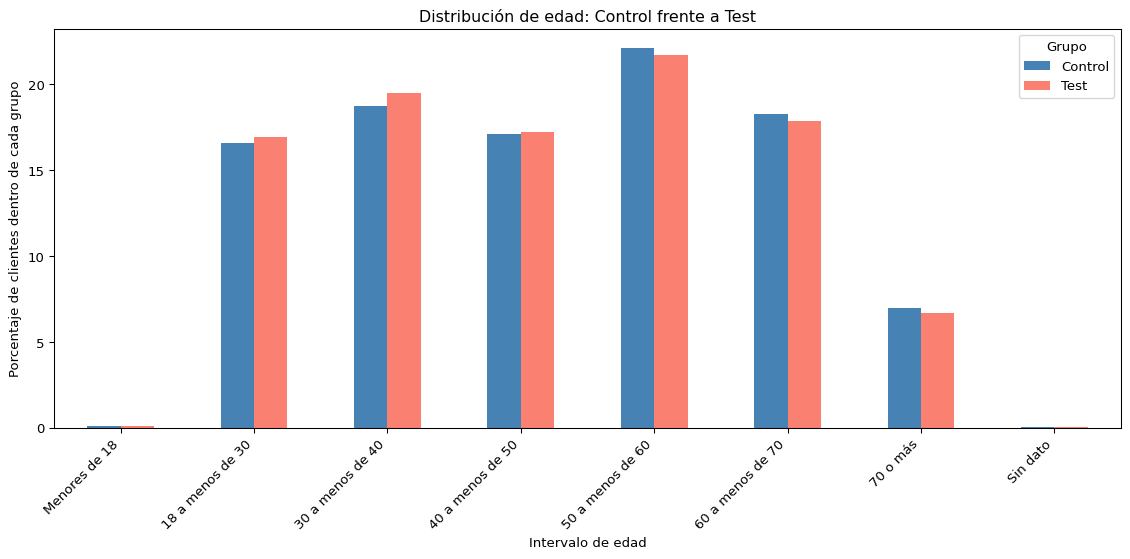

In [24]:
porcentaje_edad.T.plot(
    kind='bar',
    figsize=(12, 6),
    color=['steelblue', 'salmon']
)

plt.title("Distribución de edad: Control frente a Test")
plt.xlabel("Intervalo de edad")
plt.ylabel("Porcentaje de clientes dentro de cada grupo")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

El gráfico confirma visualmente la similitud de la distribución de edad entre Test y Control. El intervalo con mayor presencia es de 50 a menos de 60 años, con aproximadamente un 22 % en ambos grupos.

No se observan grandes diferencias por intervalo, aunque esto no demuestra por sí solo que la asignación fuera aleatoria.

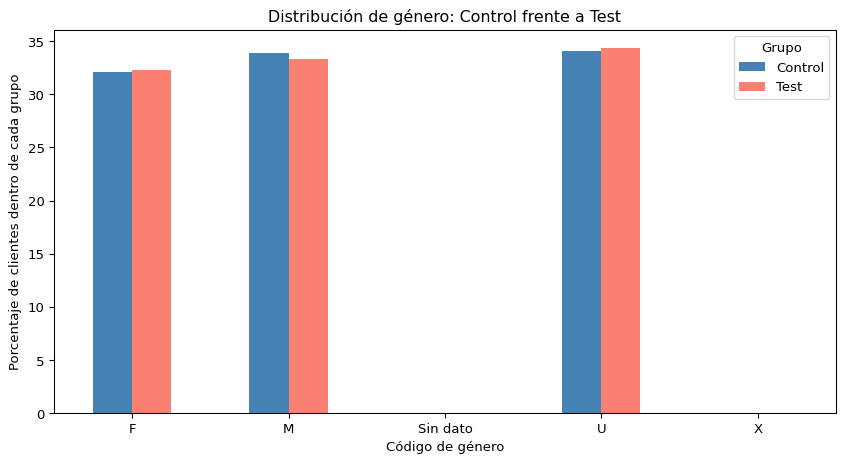

In [25]:
porcentaje_genero.T.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'salmon']
)

plt.title("Distribución de género: Control frente a Test")
plt.xlabel("Código de género")
plt.ylabel("Porcentaje de clientes dentro de cada grupo")
plt.xticks(rotation=0)
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

La distribución de los códigos de género es similar en Test y Control. `F`, `M` y `U` representan cada uno aproximadamente un tercio de cada grupo.

La mayor diferencia es de 0,58 puntos porcentuales en `M`, con mayor presencia en Control. Los códigos originales se mantienen sin reinterpretarlos.

## 15. Resumen y conclusiones de la exploración de clientes

### Datos revisados y preparación

Hemos revisado los archivos de perfiles y asignación al experimento. Ambos contienen los mismos **70.609 clientes únicos**, sin identificadores duplicados.

Los hemos unido mediante `client_id`, conservando una fila por cliente.

Para comparar las interfaces, hemos acordado utilizar los **50.500 clientes con grupo asignado**:

- **Test:** 26.968 clientes.
- **Control:** 23.532 clientes.

Los **20.109 clientes sin asignación informada** quedan fuera de esta comparación, pero se conservan en la tabla original.

### Calidad de los datos

Hemos identificado estas incidencias:

- 14 clientes tienen únicamente el identificador, sin información de perfil.
- Un cliente adicional no tiene edad registrada.
- La columna de género contiene los códigos `F`, `M`, `U` y `X`, además de nulos. Mantenemos los códigos originales porque el diccionario no especifica su significado.
- Hay 634 clientes cuya antigüedad supera su edad; 371 pertenecen a Test o Control.

No hemos corregido ni eliminado automáticamente estos registros. Al repetir las comparaciones de edad y antigüedad sin los casos dudosos, las conclusiones generales se mantienen.

### Perfil de los clientes con grupo asignado

Los participantes abarcan distintas edades. El intervalo más frecuente es **de 50 a menos de 60 años**, que representa aproximadamente el 22 % de cada grupo. Es el intervalo más numeroso, pero no constituye una mayoría.

La mediana de antigüedad es de **11 años en ambos grupos**, por lo que el perfil central corresponde a clientes con una relación de varios años con Vanguard.

Las medianas también coinciden en:

- **2 cuentas** por cliente.
- **3 llamadas** en los últimos seis meses.
- **6 accesos** a la plataforma en los últimos seis meses.

El saldo mediano ronda los **65.000–66.000**. La media es bastante mayor, debido a la influencia de los saldos elevados.

### Comparación entre Test y Control

No se observan grandes diferencias en los aspectos revisados:

- Las diferencias por intervalo de edad son inferiores a un punto porcentual.
- La mayor diferencia entre códigos de género es de 0,58 puntos porcentuales.
- La antigüedad media es de 12,09 años en Control y 11,98 en Test, con una mediana de 11 años en ambos.
- El saldo mediano es de 66.024,18 en Control y 65.468,36 en Test.
- El número de cuentas y la actividad previa presentan medias y medianas similares.

Estas similitudes son una primera señal favorable para comparar los grupos. Sin embargo, no demuestran que sean equivalentes en todas sus características ni que la asignación haya sido aleatoria.

### Alcance de las conclusiones

Esta fase describe a los clientes con grupo asignado. Todavía falta comprobar cuáles tienen actividad web registrada, por lo que aún no podemos afirmar que todos hayan utilizado el proceso.

Tampoco podemos concluir si la nueva interfaz funciona mejor: para ello necesitamos analizar los recorridos y comparar las métricas de rendimiento.

### Próximos pasos con mi compañero

1. Relacionar los clientes asignados con los eventos web preparados por mi compañero.
2. Comprobar cuántos clientes de Test y Control tienen actividad registrada.
3. Acordar el tratamiento de los clientes sin eventos, sin considerarlos abandonos automáticamente.
4. Definir las métricas del día 3, indicando si se calculan por cliente o por sesión.
5. Comparar el rendimiento de ambas interfaces y, posteriormente, realizar los contrastes de hipótesis.

## 16. Exploración y preparación de la actividad web

Los eventos del proceso están repartidos en dos archivos con las mismas columnas. Primero los cargaremos y uniré sus filas.

Después revisaremos los valores ausentes, los duplicados, las fechas y los pasos registrados antes de reconstruir los recorridos.

In [26]:
df_web_1 = pd.read_csv("data/df_final_web_data_pt_1.txt")
df_web_2 = pd.read_csv("data/df_final_web_data_pt_2.txt")

df_web = pd.concat([df_web_1, df_web_2], ignore_index=True)

print("Filas de la primera parte:", len(df_web_1))
print("Filas de la segunda parte:", len(df_web_2))
print("Filas después de unir:", len(df_web))
print("Coincide la suma:", len(df_web) == len(df_web_1) + len(df_web_2))

df_web.info()

Filas de la primera parte: 343141
Filas de la segunda parte: 412264
Filas después de unir: 755405
Coincide la suma: True
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 755405 entries, 0 to 755404
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   client_id     755405 non-null  int64 
 1   visitor_id    755405 non-null  object
 2   visit_id      755405 non-null  object
 3   process_step  755405 non-null  object
 4   date_time     755405 non-null  object
dtypes: int64(1), object(4)
memory usage: 28.8+ MB


### Resultado de la carga y unión

La primera parte contiene 343.141 filas y la segunda, 412.264. Al concatenarlas obtenemos 755.405 eventos, coincidiendo con la suma de ambos archivos.

No hay valores nulos en las cinco columnas. La columna `date_time` está almacenada como texto y deberá convertirse a fecha y hora.

Cada fila representa un evento registrado. Que un cliente o una sesión aparezcan varias veces no implica que sean duplicados.

In [27]:
print("Filas exactamente duplicadas:", df_web.duplicated().sum())

print("\nEventos por paso:")
print(df_web['process_step'].value_counts(dropna=False))

Filas exactamente duplicadas: 10764

Eventos por paso:
process_step
start      243945
step_1     163193
step_2     133062
step_3     112242
confirm    102963
Name: count, dtype: int64


## 17. Duplicados y pasos del proceso

Se han detectado 10.764 filas exactamente duplicadas. Para evitar contar varias veces el mismo registro, conservaremos una sola copia de cada combinación de las cinco columnas.

Esta decisión no elimina las visitas repetidas de un cliente ni los eventos del mismo paso con distinta fecha y hora.

Los pasos registrados son los esperados: start, step_1, step_2, step_3 y confirm. Sus frecuencias representan eventos, no clientes únicos.

In [28]:
df_web_limpio = df_web.drop_duplicates().copy()

print("Eventos conservados:", len(df_web_limpio))
print("Duplicados restantes:", df_web_limpio.duplicated().sum())

Eventos conservados: 744641
Duplicados restantes: 0


## 18. Revisión de fechas de la actividad web

Convertimos `date_time` de texto a fecha y hora para poder ordenar los eventos y calcular duraciones.

Comprobamos si hay fechas que no se pueden interpretar y cuál es el intervalo temporal registrado. El periodo indicado para el experimento es del 15 de marzo al 20 de junio de 2017.

In [29]:
df_web_limpio['date_time'] = pd.to_datetime(df_web_limpio['date_time'],errors='coerce')

print("Fechas no válidas:", df_web_limpio['date_time'].isna().sum())
print("Primera fecha:", df_web_limpio['date_time'].min())
print("Última fecha:", df_web_limpio['date_time'].max())

Fechas no válidas: 0
Primera fecha: 2017-03-15 00:03:03
Última fecha: 2017-06-20 23:59:57


### Resultado de la revisión de fechas

Todos los eventos tienen una fecha válida. El primer registro es del 15 de marzo de 2017 y el último, del 20 de junio de 2017.

El intervalo coincide con el periodo indicado para el experimento. No es necesario excluir eventos por estar fuera de esas fechas.

In [30]:
clientes_por_visita = (df_web_limpio.groupby('visit_id')['client_id'].nunique())

print("Visitas únicas:", len(clientes_por_visita))
print("Visitas asociadas a varios clientes:",
      (clientes_por_visita > 1).sum())

Visitas únicas: 158095
Visitas asociadas a varios clientes: 1012


## 19. Revisión de las sesiones

Hay 158.095 identificadores de visita distintos. De ellos, 1.012 aparecen asociados a más de un cliente.

Para evitar mezclar sus eventos, utilizaremos la combinación de `client_id` y `visit_id` al reconstruir los recorridos y calcular tiempos y retrocesos.

No eliminamos estos registros: esta comprobación no permite determinar por qué comparten el identificador de visita.

In [31]:
pasos_por_instante = (df_web_limpio.groupby(['client_id', 'visit_id', 'date_time'])['process_step'].nunique())

print("Instantes con varios pasos distintos:",(pasos_por_instante > 1).sum())

Instantes con varios pasos distintos: 943


### Eventos con la misma fecha y hora

Se han identificado 943 combinaciones de cliente, visita y fecha con más de un paso distinto.

Estos eventos se conservan. Sin embargo, su orden es ambiguo y deberá tenerse en cuenta al calcular tiempos y retrocesos: no se ordenarán artificialmente por el nombre del paso.

In [32]:
clientes_con_web = df_web_limpio['client_id'].unique()

df_experimento['tiene_actividad_web'] = (df_experimento['client_id'].isin(clientes_con_web))

pd.crosstab(df_experimento['Variation'],df_experimento['tiene_actividad_web'])

tiene_actividad_web,True
Variation,
Control,23532
Test,26968


## 20. Comprobación de actividad de los participantes

Todos los clientes con grupo asignado aparecen en los datos web:

- Control: 23.532 clientes.
- Test: 26.968 clientes.

Por tanto, la población con asignación conocida coincide con la población asignada que tiene actividad registrada.

Tener algún evento no implica haber iniciado en `start` ni haber completado el proceso.

In [33]:
df_web_experimento = df_web_limpio.merge(df_experimento[['client_id', 'Variation']],on='client_id',how='inner',validate='many_to_one')

print("Eventos de participantes:", len(df_web_experimento))
print("Clientes únicos:", df_web_experimento['client_id'].nunique())

print("\nClientes por grupo:")
print(df_web_experimento.groupby('Variation')['client_id'].nunique())

Eventos de participantes: 317235
Clientes únicos: 50500

Clientes por grupo:
Variation
Control    23532
Test       26968
Name: client_id, dtype: int64


## 21. Tasa de finalización general

Contamos una vez a cada participante. Completar significa alcanzar `confirm` en cualquier visita del periodo; no exigimos un evento `start` previo.

In [34]:
# Total de clientes únicos por grupo
clientes_por_grupo = (df_web_experimento.groupby('Variation')['client_id'].nunique())

# Clientes que tienen al menos una confirmación
clientes_completan = (df_web_experimento.loc[df_web_experimento['process_step'] == 'confirm'].groupby('Variation')['client_id'].nunique())

# Reunir los recuentos y calcular el porcentaje
resumen_finalizacion = pd.DataFrame({'clientes': clientes_por_grupo,'completan': clientes_completan}).fillna(0)

resumen_finalizacion['tasa_finalizacion'] = (resumen_finalizacion['completan'] /resumen_finalizacion['clientes'] * 100)

resumen_finalizacion.round(2)

,clientes,completan,tasa_finalizacion
Variation,,,
Control,23532,15434,65.59
Test,26968,18687,69.29


### Resultado de la tasa de finalización

El 69,29 % de los clientes de Test alcanza la confirmación, frente al 65,59 % de Control.

La diferencia es de 3,70 puntos porcentuales, equivalente a una mejora relativa del 5,65 %, calculada con las tasas sin redondear.

Este resultado descriptivo favorece al nuevo diseño. Los contrastes posteriores evalúan la diferencia general y el umbral del 5 % relativo acordado para el proyecto.

## 22. Tiempo transcurrido en cada paso

Estimaremos el tiempo de cada paso como la diferencia entre su fecha y la del siguiente evento del mismo cliente y visita.

El último evento de una visita no tiene duración observable. Tampoco interpretaremos el tiempo posterior a `confirm` como tiempo necesario para completar.

Antes del cálculo, identificaremos los instantes con pasos distintos registrados a la misma hora, porque no podemos determinar su orden.

In [35]:
# Ordenar los eventos dentro de cada recorrido
df_web_experimento = df_web_experimento.sort_values(['client_id', 'visit_id', 'date_time']).copy()

# Identificar instantes con más de un paso distinto
pasos_misma_hora = (df_web_experimento.groupby(['client_id', 'visit_id', 'date_time'])['process_step'].transform('nunique'))

df_web_experimento['orden_ambiguo'] = pasos_misma_hora > 1

print("Eventos en instantes con orden ambiguo:",df_web_experimento['orden_ambiguo'].sum())

Eventos en instantes con orden ambiguo: 1052


In [36]:
# Siguiente evento del mismo cliente y visita
sesiones = df_web_experimento.groupby(['client_id', 'visit_id'])

df_web_experimento['fecha_siguiente'] = (sesiones['date_time'].shift(-1))

df_web_experimento['siguiente_ambiguo'] = (sesiones['orden_ambiguo'].shift(-1))

# Duración en segundos
df_web_experimento['duracion_segundos'] = (df_web_experimento['fecha_siguiente'] -df_web_experimento['date_time']).dt.total_seconds()

# Seleccionar intervalos que podemos interpretar
intervalos_validos = ((~df_web_experimento['orden_ambiguo']) &(df_web_experimento['siguiente_ambiguo'] == False) &(df_web_experimento['duracion_segundos'] > 0) &(df_web_experimento['process_step'] != 'confirm')
)

df_tiempos = df_web_experimento.loc[intervalos_validos].copy()

resumen_tiempos = (df_tiempos.groupby(['Variation', 'process_step'])['duracion_segundos'].agg(['count', 'mean', 'median', 'max']).round(2))

resumen_tiempos

count    mean  median      max
Variation process_step                                
Control   start         35730   66.84    20.0  40235.0
          step_1        26016   50.52    20.0  10286.0
          step_2        24175   92.23    64.0  21763.0
          step_3        19814  138.03    73.0   6164.0
Test      start         46296   61.49    14.0  24819.0
          step_1        35437   60.77    27.0   8797.0
          step_2        29406   89.23    61.0  11204.0
          step_3        23780  129.98    58.0   6692.0

### Primera comparación de tiempos por paso

Test presenta tiempos medios y medianos menores en el inicio y en los pasos 2 y 3. Sin embargo, en el paso 1 los tiempos son mayores: la mediana pasa de 20 segundos en Control a 27 en Test.

El paso 3 tiene el mayor tiempo medio en ambos grupos. Su mediana baja de 73 a 58 segundos con la nueva interfaz.

Se observan intervalos de varias horas que pueden incluir pausas. Por eso, las medias se interpretan junto con las medianas. No se han eliminado automáticamente los intervalos largos.

Estos resultados describen intervalos observables entre eventos, incluyendo repeticiones y retrocesos. No representan necesariamente el tiempo de avance correcto ni permiten concluir que una menor duración sea siempre una mejora.

In [37]:
porcentaje_pausas = (df_tiempos.assign(supera_30_min=df_tiempos['duracion_segundos'] > 1800).groupby(['Variation', 'process_step'])['supera_30_min'].mean() * 100)

porcentaje_pausas.round(2)

Variation  process_step
Control    start           0.18
           step_1          0.10
           step_2          0.05
           step_3          0.14
Test       start           0.19
           step_1          0.08
           step_2          0.02
           step_3          0.19
Name: supera_30_min, dtype: float64

### Comprobación de sensibilidad a las pausas largas

Los intervalos superiores a 30 minutos representan entre el 0,02 % y el 0,19 % de los intervalos válidos por paso y grupo.

Repetimos el resumen excluyéndolos únicamente para comprobar su influencia. El umbral de 30 minutos es una referencia exploratoria, no una regla establecida por Vanguard ni una prueba de que esos registros sean errores.

Los datos y el cálculo principal se conservan.

In [38]:
resumen_tiempos_sin_pausas = (df_tiempos.loc[df_tiempos['duracion_segundos'] <= 1800].groupby(['Variation', 'process_step'])['duracion_segundos'].agg(['count', 'mean', 'median']).round(2))

resumen_tiempos_sin_pausas

count    mean  median
Variation process_step                       
Control   start         35665   60.89    20.0
          step_1        25990   47.51    20.0
          step_2        24164   90.39    64.0
          step_3        19786  134.19    73.0
Test      start         46210   56.27    14.0
          step_1        35409   58.58    27.0
          step_2        29401   88.48    61.0
          step_3        23734  125.13    58.0

### Conclusión sobre los tiempos por paso

Al excluir los intervalos superiores a 30 minutos, las medias disminuyen, pero se mantiene el patrón observado:

- Test registra tiempos menores en `start`, `step_2` y `step_3`.
- En `step_1`, Test registra tiempos mayores que Control.
- Las medianas no cambian en ningún paso ni grupo.

Por tanto, las pausas largas no explican la dirección de las diferencias. Conservamos como resultado principal el cálculo con todos los intervalos válidos y utilizamos esta comparación como comprobación adicional.

La nueva interfaz no reduce los tiempos en todos los pasos. El paso 1 merece atención al analizar los retrocesos y la finalización.

## 23. Tasa de retrocesos

Según el enunciado, consideramos error una transición hacia un paso anterior dentro del mismo cliente y visita.

Calculamos:

Número de retrocesos / número de transiciones evaluables × 100.

Excluimos las transiciones cuyo origen o destino tiene un orden ambiguo y los eventos sin siguiente paso. Las repeticiones del mismo paso cuentan en el denominador, pero no como errores.

Esta métrica describe retrocesos registrados; no demuestra por sí sola que exista un fallo técnico.

In [39]:
# Asignar un orden a los pasos
orden_pasos = {'start': 0,'step_1': 1,'step_2': 2,'step_3': 3,'confirm': 4}

df_web_experimento['orden_paso'] = (df_web_experimento['process_step'].map(orden_pasos))

# Obtener el siguiente paso dentro del mismo cliente y visita
df_web_experimento['orden_siguiente'] = (df_web_experimento.groupby(['client_id', 'visit_id'])['orden_paso'].shift(-1))

# Seleccionar transiciones cuyo orden podemos interpretar
transiciones_validas = ((~df_web_experimento['orden_ambiguo']) &(df_web_experimento['siguiente_ambiguo'] == False) &(df_web_experimento['orden_siguiente'].notna()) &(df_web_experimento['duracion_segundos'] > 0))

df_transiciones = df_web_experimento.loc[transiciones_validas].copy()

df_transiciones['retroceso'] = (df_transiciones['orden_siguiente'] < df_transiciones['orden_paso'])

resumen_errores = (df_transiciones.groupby('Variation')['retroceso'].agg(['count', 'sum', 'mean']).rename(columns={'count': 'transiciones_evaluables','sum': 'retrocesos','mean': 'tasa_retrocesos'}))

resumen_errores['tasa_retrocesos'] *= 100

resumen_errores.round(2)

,transiciones_evaluables,retrocesos,tasa_retrocesos
Variation,,,
Control,107550,9318,8.66
Test,138990,15980,11.50


### Resultado de la tasa de retrocesos

En Control se registran 9.318 retrocesos entre 107.550 transiciones evaluables (8,66 %). En Test aparecen 15.980 entre 138.990 transiciones (11,50 %).

La nueva interfaz presenta una tasa de retrocesos aproximadamente 2,84 puntos porcentuales superior. Este porcentaje se refiere a transiciones, no a clientes: una persona puede retroceder varias veces.

El resultado contrasta con la mayor tasa de finalización de Test. La nueva interfaz consigue que más clientes lleguen a confirmar, pero sus recorridos también presentan más movimientos hacia pasos anteriores.

Los retrocesos pueden señalar dificultades, aunque no demuestran errores técnicos. Además, el cálculo incluye movimientos posteriores a `confirm`, que podrían corresponder a nuevas acciones dentro de la misma visita.

Estos resultados son descriptivos y todavía no hemos contrastado estadísticamente sus diferencias.

### 24. Finalización en la primera visita observada

Calculamos el porcentaje de clientes que alcanza el paso `confirm`
durante su primera visita registrada en los datos.

Esta métrica nos permite comparar si los clientes de Test y Control
consiguen completar el proceso desde esa primera visita.

La primera visita observada no tiene por qué ser la primera visita
que el cliente haya realizado en su vida.

In [40]:
# Identificar los eventos de confirmación
df_web_experimento['es_confirmacion'] = (df_web_experimento['process_step'] == 'confirm')

# Resumir cada visita de cada cliente
resumen_visitas = (df_web_experimento.groupby(['client_id', 'visit_id', 'Variation']).agg(inicio_visita=('date_time', 'min'),completa=('es_confirmacion', 'max')).reset_index()
)

# Identificar la primera fecha de visita de cada cliente
primer_inicio = (resumen_visitas.groupby('client_id')['inicio_visita'].transform('min'))

primeras_visitas = resumen_visitas.loc[resumen_visitas['inicio_visita'] == primer_inicio].copy()

# Comprobar si hay clientes con varias visitas iniciadas a la vez
visitas_por_cliente = primeras_visitas.groupby('client_id').size()

print("Clientes con primera visita:", primeras_visitas['client_id'].nunique())
print("Clientes con empate en la primera visita:", (visitas_por_cliente > 1).sum())

Clientes con primera visita: 50500
Clientes con empate en la primera visita: 0


In [41]:
# Calcular la finalización en la primera visita por grupo
resumen_primera_visita = (
    primeras_visitas
    .groupby('Variation')
    .agg(
        clientes=('client_id', 'count'),
        completan_primera_visita=('completa', 'sum')
    )
)

# Expresar la tasa como porcentaje
resumen_primera_visita['tasa_finalizacion_primera_visita'] = (
    resumen_primera_visita['completan_primera_visita']
    / resumen_primera_visita['clientes'] * 100
)

resumen_primera_visita.round(2)

,clientes,completan_primera_visita,tasa_finalizacion_primera_visita
Variation,,,
Control,23532,12564,53.39
Test,26968,15412,57.15


#### Interpretación

El 57,15 % de los clientes de Test completa el proceso en su primera
visita observada, frente al 53,39 % de Control. La diferencia es de
3,76 puntos porcentuales a favor del nuevo diseño.

Al considerar todas las visitas, las tasas de finalización aumentan
al 69,29 % en Test y al 65,59 % en Control. Por tanto, en ambos grupos
hay clientes que completan el proceso en visitas posteriores.

El nuevo diseño presenta mejores resultados de finalización tanto
en la primera visita como en el conjunto del periodo. Todavía debemos
comprobar si estas diferencias son estadísticamente significativas.

Esta métrica indica si el cliente llega a confirmar durante la primera
visita registrada, aunque haya retrocedido o repetido pasos dentro de ella.

### 25. Último paso de las visitas sin confirmación

Identificamos el último paso registrado en cada visita que no alcanza
`confirm` y comparamos su distribución entre Test y Control.

Una visita sin confirmación no implica que el cliente abandone
definitivamente: podría completar el proceso en otra visita.

Si aparecen varios pasos distintos en el último instante de una visita,
la clasificamos como «Orden ambiguo», sin elegir un paso arbitrariamente.

In [42]:
# Localizar los eventos del último instante de cada visita
ultima_fecha = (
    df_web_experimento
    .groupby(['client_id', 'visit_id'])['date_time']
    .transform('max')
)

eventos_finales = df_web_experimento.loc[
    df_web_experimento['date_time'] == ultima_fecha
]

# Comprobar si el último paso se puede identificar
ultimos_pasos = (
    eventos_finales
    .groupby(['client_id', 'visit_id'])
    .agg(
        ultimo_paso=('process_step', 'first'),
        pasos_distintos=('process_step', 'nunique')
    )
    .reset_index()
)

ultimos_pasos.loc[
    ultimos_pasos['pasos_distintos'] > 1, 'ultimo_paso'
] = 'Orden ambiguo'

# Añadir el último paso al resumen de visitas
visitas_con_final = resumen_visitas.merge(
    ultimos_pasos,
    on=['client_id', 'visit_id'],
    how='left',
    validate='one_to_one'
)

# Seleccionar las visitas que no llegaron a confirmar
visitas_sin_confirmar = visitas_con_final.loc[
    visitas_con_final['completa'] == False
].copy()

# Número de visitas sin confirmar según su último paso
recuento_ultimo_paso = pd.crosstab(
    visitas_sin_confirmar['Variation'],
    visitas_sin_confirmar['ultimo_paso']
)

# Porcentaje dentro de las visitas sin confirmar de cada grupo
porcentaje_ultimo_paso = pd.crosstab(
    visitas_sin_confirmar['Variation'],
    visitas_sin_confirmar['ultimo_paso'],
    normalize='index'
) * 100

print("Número de visitas sin confirmar por último paso:")
display(recuento_ultimo_paso)

print("Distribución porcentual:")
display(porcentaje_ultimo_paso.round(2))

Número de visitas sin confirmar por último paso:
Distribución porcentual:


ultimo_paso,Orden ambiguo,start,step_1,step_2,step_3
Variation,,,,,
Control,14,9445,3118,1453,2125
Test,16,9328,2989,1322,1758


ultimo_paso,Orden ambiguo,start,step_1,step_2,step_3
Variation,,,,,
Control,0.09,58.46,19.30,8.99,13.15
Test,0.10,60.52,19.39,8.58,11.41


#### Interpretación

Entre las visitas que no llegan a confirmar, el último paso más frecuente
es `start`: representa el 58,46 % en Control y el 60,52 % en Test.
Por tanto, el inicio es un punto relevante para investigar posibles
dificultades o motivos de interrupción.

El segundo paso final más frecuente es `step_1`, con aproximadamente
un 19 % en ambos grupos.

Las visitas sin confirmación que terminan en `step_3` representan
el 13,15 % en Control y el 11,41 % en Test.

Estos porcentajes describen dónde terminan las visitas sin confirmar.
No indican la probabilidad de abandonar al llegar a cada paso ni
permiten concluir, por sí solos, que un diseño funciona mejor.

El último paso registrado tampoco es necesariamente el más avanzado
que alcanzó el cliente, ya que puede haber retrocedido.

Hay 14 visitas de Control y 16 de Test cuyo último paso no podemos
determinar por tener varios pasos registrados en el mismo instante.
Las mantenemos como «Orden ambiguo».

### 26. Clientes con al menos un retroceso

Calculamos el porcentaje de clientes con algún retroceso observado
en las transiciones que podemos evaluar.

Esta métrica permite conocer a cuántos clientes afecta este comportamiento,
independientemente del número de veces que retrocedan.

Usamos como denominador los clientes con al menos una transición evaluable.
Los clientes sin transiciones evaluables quedan fuera, porque no podemos
determinar si retrocedieron.

In [43]:
# Identificar si cada cliente tiene algún retroceso
retrocesos_por_cliente = (
    df_transiciones
    .groupby(['Variation', 'client_id'])
    .agg(
        tiene_retroceso=('retroceso', 'max')
    )
    .reset_index()
)

# Resumir los resultados por grupo
resumen_clientes_retroceso = (
    retrocesos_por_cliente
    .groupby('Variation')
    .agg(
        clientes_evaluables=('client_id', 'count'),
        clientes_con_retroceso=('tiene_retroceso', 'sum')
    )
)

# Calcular el porcentaje
resumen_clientes_retroceso['porcentaje_con_retroceso'] = (
    resumen_clientes_retroceso['clientes_con_retroceso']
    / resumen_clientes_retroceso['clientes_evaluables'] * 100
)

resumen_clientes_retroceso.round(2)

,clientes_evaluables,clientes_con_retroceso,porcentaje_con_retroceso
Variation,,,
Control,21117,6020,28.51
Test,25446,8973,35.26


#### Interpretación

El 35,26 % de los clientes evaluables de Test realiza al menos un
retroceso, frente al 28,51 % de Control: una diferencia de
6,75 puntos porcentuales.

Este resultado complementa la tasa de retrocesos por transición:
en Test, los retrocesos representan una mayor proporción de los
movimientos y también afectan a un mayor porcentaje de clientes evaluables.

Aunque Test presenta una mayor finalización, también registra más
retrocesos. Esto sugiere que conviene investigar qué pasos generan
dificultades. Retroceder no demuestra necesariamente un error:
el cliente podría volver para revisar o corregir información.

La comparación incluye únicamente a clientes con alguna transición
evaluable: 21.117 en Control y 25.446 en Test. Quedan fuera 2.415
y 1.522 clientes, respectivamente. Esta diferencia de cobertura debe
tenerse en cuenta al interpretar los porcentajes.

Los resultados son descriptivos; todavía no hemos contrastado
estadísticamente la diferencia.

### 27. Clientes con varias visitas

Calculamos el porcentaje de clientes que tiene dos o más visitas
registradas durante el periodo del experimento.

Cada cliente cuenta una sola vez. Usamos como denominador todos
los clientes de cada grupo.

Tener varias visitas no implica necesariamente una dificultad:
el cliente puede volver tras interrumpir el proceso o después de
haberlo completado.

In [44]:
# Contar las visitas de cada cliente
visitas_por_cliente = (
    resumen_visitas
    .groupby(['Variation', 'client_id'])
    .size()
    .reset_index(name='numero_visitas')
)

# Identificar a los clientes con dos o más visitas
visitas_por_cliente['varias_visitas'] = (
    visitas_por_cliente['numero_visitas'] >= 2
)

# Resumir los resultados por grupo
resumen_varias_visitas = (
    visitas_por_cliente
    .groupby('Variation')
    .agg(
        clientes=('client_id', 'count'),
        clientes_varias_visitas=('varias_visitas', 'sum')
    )
)

# Calcular el porcentaje
resumen_varias_visitas['porcentaje_varias_visitas'] = (
    resumen_varias_visitas['clientes_varias_visitas']
    / resumen_varias_visitas['clientes'] * 100
)

resumen_varias_visitas.round(2)

,clientes,clientes_varias_visitas,porcentaje_varias_visitas
Variation,,,
Control,23532,5904,25.09
Test,26968,7092,26.30


#### Interpretación

El 26,30 % de los clientes de Test registra dos o más visitas durante
el experimento, frente al 25,09 % de Control. La diferencia observada
es de 1,21 puntos porcentuales.

La proporción de clientes con varias visitas es parecida en ambos grupos,
aunque ligeramente mayor en Test.

Esta métrica no permite afirmar que el nuevo diseño obligue a realizar
más intentos para completar el proceso. Las visitas adicionales pueden
producirse tanto antes como después de una confirmación.

Para entender los motivos de estas visitas, sería necesario analizar
su secuencia y si el cliente ya había completado el proceso.

### 28. Tasa de finalización por grupo de edad

Comparamos el porcentaje de clientes que alcanza `confirm` dentro
de cada grupo de edad, separando Test y Control.

Cada cliente cuenta una sola vez, aunque confirme en varias visitas.
Mantenemos la misma definición que en la tasa de finalización general:
haber alcanzado `confirm` en algún momento del periodo.

Mostramos también el número de clientes de cada segmento para
interpretar los porcentajes teniendo en cuenta su tamaño.

In [45]:
# Identificar a los clientes que completan el proceso
clientes_con_confirmacion = df_web_experimento.loc[
    df_web_experimento['process_step'] == 'confirm',
    'client_id'
].unique()

# Copiar los perfiles de los participantes
df_metricas_clientes = df_experimento.copy()

# Marcar si cada cliente completa durante el periodo
df_metricas_clientes['completa'] = (
    df_metricas_clientes['client_id'].isin(clientes_con_confirmacion)
)

# Calcular la finalización por edad y grupo experimental
resumen_finalizacion_edad = (
    df_metricas_clientes
    .groupby(['grupo_edad', 'Variation'], observed=True)
    .agg(
        clientes=('client_id', 'count'),
        completan=('completa', 'sum')
    )
    .reset_index()
)

resumen_finalizacion_edad['tasa_finalizacion'] = (
    resumen_finalizacion_edad['completan']
    / resumen_finalizacion_edad['clientes'] * 100
)

resumen_finalizacion_edad.round(2)

,grupo_edad,Variation,clientes,completan,tasa_finalizacion
0,Menores de 18,Control,28,28,100.00
1,Menores de 18,Test,34,34,100.00
2,18 a menos de 30,Control,3907,2633,67.39
3,18 a menos de 30,Test,4562,3386,74.22
4,30 a menos de 40,Control,4416,2970,67.26
5,30 a menos de 40,Test,5257,3686,70.12
6,40 a menos de 50,Control,4026,2743,68.13
7,40 a menos de 50,Test,4641,3250,70.03
8,50 a menos de 60,Control,5208,3467,66.57
9,50 a menos de 60,Test,5850,4012,68.58


#### Interpretación

Test presenta una tasa de finalización superior a Control en todos
los grupos de edad adultos.

La mayor diferencia observada corresponde a los clientes de 18 a
menos de 30 años: el 74,22 % completa en Test frente al 67,39 %
en Control, una diferencia de 6,83 puntos porcentuales.

Los clientes de 70 años o más presentan la menor finalización en
ambos grupos: 51,89 % en Control y 57,05 % en Test. Aunque Test
obtiene un mejor resultado, este segmento merece atención para
investigar posibles dificultades durante el proceso.

Los menores de 18 años alcanzan un 100 % en ambos grupos, pero
solo contamos con 28 clientes en Control y 34 en Test. El grupo
sin edad informada también es muy pequeño. No generalizamos
estos resultados.

Este análisis conserva los perfiles con inconsistencias entre edad
y antigüedad que habíamos identificado. Antes de realizar contrastes
sobre la edad, revisaremos la sensibilidad de los resultados a esos casos.

Las diferencias son descriptivas: todavía no podemos afirmar que
sean estadísticamente significativas ni que la edad cause las
dificultades de finalización.

### 29. Tasa de finalización por nivel de saldo

Dividimos a los participantes en cuatro grupos según su saldo,
utilizando los cuartiles del conjunto de Test y Control.

Aplicamos los mismos límites a ambos grupos para que la comparación
sea consistente. Estas categorías son relativas a nuestra muestra;
no representan segmentos comerciales oficiales de Vanguard.

Conservamos los saldos elevados y clasificamos los valores ausentes
como «Sin dato». Después calculamos la finalización dentro de cada
nivel de saldo y grupo experimental.

In [46]:
# Crear cuatro niveles de saldo con límites comunes
grupos_saldo, limites_saldo = pd.qcut(
    df_metricas_clientes['bal'],
    q=4,
    labels=['Saldo bajo', 'Saldo medio-bajo',
            'Saldo medio-alto', 'Saldo alto'],
    retbins=True
)

df_metricas_clientes['grupo_saldo'] = (
    grupos_saldo
    .cat.add_categories('Sin dato')
    .fillna('Sin dato')
)

# Mostrar los límites para interpretar los grupos
print("Límites de los grupos de saldo:")
print(limites_saldo.round(2))

# Calcular la finalización por nivel de saldo
resumen_finalizacion_saldo = (
    df_metricas_clientes
    .groupby(['grupo_saldo', 'Variation'], observed=True)
    .agg(
        clientes=('client_id', 'count'),
        completan=('completa', 'sum')
    )
    .reset_index()
)

resumen_finalizacion_saldo['tasa_finalizacion'] = (
    resumen_finalizacion_saldo['completan']
    / resumen_finalizacion_saldo['clientes'] * 100
)

display(resumen_finalizacion_saldo.round(2))

Límites de los grupos de saldo:
[   23789.44    39878.41    65733.6    139956.54 16320040.15]


,grupo_saldo,Variation,clientes,completan,tasa_finalizacion
0,Saldo bajo,Control,5817,3818,65.64
1,Saldo bajo,Test,6805,4729,69.49
2,Saldo medio-bajo,Control,5899,3846,65.20
3,Saldo medio-bajo,Test,6723,4624,68.78
4,Saldo medio-alto,Control,5906,3830,64.85
5,Saldo medio-alto,Test,6716,4612,68.67
6,Saldo alto,Control,5905,3935,66.64
7,Saldo alto,Test,6717,4717,70.22
8,Sin dato,Control,5,5,100.00
9,Sin dato,Test,7,5,71.43


#### Interpretación

Test presenta mayor finalización que Control en todos los niveles
de saldo. Las diferencias oscilan entre 3,58 y 3,85 puntos porcentuales,
por lo que la ventaja observada de Test es similar en estos segmentos.

El grupo de saldo alto registra la mayor finalización: 66,64 % en
Control y 70,22 % en Test. Sin embargo, las tasas no aumentan
progresivamente con el saldo.

Los límites aproximados de los grupos son:
- Saldo bajo: hasta 39.878,41.
- Saldo medio-bajo: más de 39.878,41 y hasta 65.733,60.
- Saldo medio-alto: más de 65.733,60 y hasta 139.956,54.
- Saldo alto: más de 139.956,54.

El grupo sin saldo informado solo contiene 5 clientes en Control
y 7 en Test, por lo que sus porcentajes no permiten generalizar.

Estos resultados son descriptivos y no demuestran que el saldo
cause diferencias en la finalización.

### 30. Tasa de finalización por antigüedad

Comparamos la finalización según los años que el cliente lleva
en Vanguard, utilizando los mismos tramos para Test y Control.

Cada cliente cuenta una sola vez y los valores ausentes se mantienen
como «Sin dato». Conservamos los casos con inconsistencias entre
edad y antigüedad, pendientes de revisar mediante un análisis
de sensibilidad.

In [47]:
# Crear grupos de antigüedad
df_metricas_clientes['grupo_antiguedad'] = pd.cut(
    df_metricas_clientes['clnt_tenure_yr'],
    bins=[0, 5, 10, 20, float('inf')],
    labels=[
        'Menos de 5 años',
        '5 a menos de 10',
        '10 a menos de 20',
        '20 años o más'
    ],
    right=False
)

df_metricas_clientes['grupo_antiguedad'] = (
    df_metricas_clientes['grupo_antiguedad']
    .cat.add_categories('Sin dato')
    .fillna('Sin dato')
)

# Calcular la finalización por antigüedad
resumen_finalizacion_antiguedad = (
    df_metricas_clientes
    .groupby(['grupo_antiguedad', 'Variation'], observed=True)
    .agg(
        clientes=('client_id', 'count'),
        completan=('completa', 'sum')
    )
    .reset_index()
)

resumen_finalizacion_antiguedad['tasa_finalizacion'] = (
    resumen_finalizacion_antiguedad['completan']
    / resumen_finalizacion_antiguedad['clientes'] * 100
)

resumen_finalizacion_antiguedad.round(2)

,grupo_antiguedad,Variation,clientes,completan,tasa_finalizacion
0,Menos de 5 años,Control,1746,1161,66.49
1,Menos de 5 años,Test,2033,1391,68.42
2,5 a menos de 10,Control,8713,5785,66.40
3,5 a menos de 10,Test,10156,7158,70.48
4,10 a menos de 20,Control,9249,5990,64.76
5,10 a menos de 20,Test,10514,7153,68.03
6,20 años o más,Control,3819,2493,65.28
7,20 años o más,Test,4258,2980,69.99
8,Sin dato,Control,5,5,100.00
9,Sin dato,Test,7,5,71.43


#### Interpretación

Test presenta una tasa de finalización superior a Control en todos
los tramos de antigüedad.

La mayor diferencia observada corresponde a los clientes con 20 años
o más en Vanguard: 69,99 % en Test frente al 65,28 % en Control.
La menor diferencia aparece entre quienes llevan menos de 5 años:
68,42 % frente al 66,49 %.

No observamos una relación progresiva entre antigüedad y finalización:
llevar más años como cliente no se corresponde necesariamente con
una mayor tasa de finalización.

El tramo de 10 a menos de 20 años presenta la menor finalización
en ambos grupos, aunque las diferencias respecto a los otros tramos
son moderadas.

Los clientes sin información de antigüedad son muy pocos, por lo
que no generalizamos sus resultados. También mantenemos pendiente
la revisión de los casos con antigüedad superior a la edad.

Estas diferencias son descriptivas. Todavía no podemos afirmar
que sean estadísticamente significativas ni que el efecto del
nuevo diseño cambie según la antigüedad.

## Contraste 1. Tasa de finalización de Test frente a Control

Queremos comprobar si el nuevo diseño presenta una tasa de
finalización superior a la del diseño antiguo.

- H₀: la tasa de finalización de Test es igual o inferior a Control.
- H₁: la tasa de finalización de Test es superior a Control.

Utilizamos un nivel de significación de 0,05 y un test t de Welch
unilateral sobre la finalización codificada como 0 y 1.

Cada cliente cuenta una sola vez. Consideramos que completa si
alcanza `confirm` en algún momento del periodo del experimento.
Incluimos a todos los participantes asignados a Test o Control,
que en nuestros datos tienen actividad web registrada.

In [48]:
# Comprobar que tenemos una fila por cliente
print(
    "Identificadores duplicados:",
    df_metricas_clientes['client_id'].duplicated().sum()
)

# Contar clientes que completan y que no completan
tabla_finalizacion = pd.crosstab(
    df_metricas_clientes['Variation'],
    df_metricas_clientes['completa']
)

tabla_finalizacion = tabla_finalizacion.reindex(
    index=['Control', 'Test'],
    columns=[False, True],
    fill_value=0
)

tabla_finalizacion.columns = ['no_completan', 'completan']

display(tabla_finalizacion)

Identificadores duplicados: 0


,no_completan,completan
Variation,,
Control,8098,15434
Test,8281,18687


Utilizamos un test t de Welch unilateral sobre la finalización
codificada como 1 si el cliente completa y 0 si no completa.
La media de esta variable equivale a la tasa de finalización.

Aunque los datos individuales son binarios, el gran tamaño de
ambos grupos permite utilizar una aproximación para comparar
sus medias. Suponemos independencia entre clientes y no exigimos
que las varianzas de ambos grupos sean iguales.

El nivel de significación es 0,05.

In [49]:
import scipy.stats as st

# Una observación por cliente: 1 si completa y 0 si no
finalizacion_test = df_metricas_clientes.loc[
    df_metricas_clientes['Variation'] == 'Test',
    'completa'
].astype(int)

finalizacion_control = df_metricas_clientes.loc[
    df_metricas_clientes['Variation'] == 'Control',
    'completa'
].astype(int)

# Test t de Welch unilateral: Test > Control
estadistico, p_valor = st.ttest_ind(
    finalizacion_test,
    finalizacion_control,
    equal_var=False,
    alternative='greater'
)

print("Estadístico t:", estadistico)
print("P-valor:", p_valor)
print("Nivel de significación:", 0.05)

Estadístico t: 8.863468067325087
P-valor: 4.0048843353918406e-19
Nivel de significación: 0.05


### Resultado e interpretación del contraste

Aplicamos un test t de Welch unilateral sobre la finalización
codificada como 1 si el cliente completa y 0 si no completa.
La media de esta variable representa la tasa de finalización.

- Estadístico t: 8,86.
- P-valor: aproximadamente 4,00 × 10⁻¹⁹.
- Nivel de significación: 0,05.

Como el p-valor es inferior a 0,05, rechazamos H₀. Los datos aportan
evidencia estadística de que la tasa de finalización de Test es
superior a la de Control.

En la muestra, completa el 69,29 % de Test frente al 65,59 % de
Control. La diferencia es de 3,70 puntos porcentuales, equivalente
a una mejora relativa aproximada del 5,65 %.

El contraste utiliza una observación por cliente, supone independencia
entre clientes y se apoya en el gran tamaño de ambos grupos para
comparar las medias de una variable binaria.

Este resultado demuestra una diferencia estadísticamente significativa,
pero no permite afirmar todavía que la mejora real supere el umbral
del 5 % relativo exigido por Vanguard. Eso corresponde al siguiente
contraste.

## Contraste 2. Mejora mínima del 5 % relativo

Vanguard exige una mejora relativa mínima del 5 % en la tasa
de finalización para justificar el coste del nuevo diseño.

- H₀: la tasa de Test es igual o inferior a 1,05 veces la tasa
  de Control.
- H₁: la tasa de Test es superior a 1,05 veces la tasa de Control.

Utilizamos un nivel de significación de 0,05.

Aplicamos un test t de Welch unilateral, comparando la finalización
de Test con la finalización de Control multiplicada por 1,05.
La media de esta segunda variable equivale a 1,05 veces la tasa
de finalización de Control.

Es una aproximación basada en el gran tamaño de ambos grupos.
Mantenemos una observación por cliente y suponemos independencia
entre clientes.

In [50]:
# Calcular la mejora observada sin redondear las tasas
tasa_test = finalizacion_test.mean()
tasa_control = finalizacion_control.mean()

mejora_relativa = (tasa_test / tasa_control - 1) * 100

print("Mejora relativa observada (%):", mejora_relativa)
print("Tasa mínima requerida para Test (%):", tasa_control * 1.05 * 100)

# Ajustar Control al umbral del 5 % relativo
control_umbral = finalizacion_control * 1.05

# Contrastar si Test supera ese umbral
estadistico_umbral, p_valor_umbral = st.ttest_ind(
    finalizacion_test,
    control_umbral,
    equal_var=False,
    alternative='greater'
)

print("Estadístico t:", estadistico_umbral)
print("P-valor:", p_valor_umbral)
print("Nivel de significación:", 0.05)

Mejora relativa observada (%): 5.650410757558411
Tasa mínima requerida para Test (%): 68.86664966853647
Estadístico t: 0.9927284774092082
P-valor: 0.16042363376348037
Nivel de significación: 0.05


### Resultado e interpretación del contraste

- Mejora relativa observada: 5,65 %.
- Tasa mínima requerida para Test según la tasa observada de Control:
  68,87 %.
- Tasa observada de Test: 69,29 %.
- Estadístico t: 0,99.
- P-valor: 0,1604.
- Nivel de significación: 0,05.

Como el p-valor es superior a 0,05, no rechazamos H₀.
No contamos con evidencia estadística suficiente para afirmar que
la mejora real de Test supere el umbral del 5 % relativo.

Aunque la mejora observada en la muestra supera ese umbral,
la incertidumbre del resultado impide concluir que se supera
también en la población.

Esto no demuestra que la mejora sea inferior al 5 % ni que
el nuevo diseño no sea rentable.

### Conclusión conjunta de los dos contrastes

El primer contraste aporta evidencia de que Test tiene una tasa
de finalización superior a Control.

La mejora observada del 5,65 % supera el umbral del 5 % relativo establecido por Vanguard. Sin embargo, el contraste no permite afirmar con suficiente evidencia estadística que la mejora real supere dicho umbral.

## Contraste 3. Relación entre edad y finalización

Queremos comprobar si la finalización está relacionada con el grupo
de edad. Realizaremos el análisis por separado en Control y Test.

- H₀: el grupo de edad y la finalización son independientes.
- H₁: existe asociación entre el grupo de edad y la finalización.

Utilizaremos un contraste chi-cuadrado de independencia.

Excluimos de este análisis a los clientes sin edad informada,
porque no podemos asignarlos a un tramo de edad.

Primero analizaremos los clientes con edad disponible. Después
repetiremos el análisis excluyendo los casos cuya antigüedad en
meses supera su edad multiplicada por 12, para comprobar si
estos casos cambian la conclusión.

Cada cliente cuenta una sola vez. El contraste supone independencia
entre clientes y requiere revisar las frecuencias esperadas.

In [51]:
# Clientes con edad informada
df_edad = df_metricas_clientes.loc[
    df_metricas_clientes['clnt_age'].notna()
].copy()

# Identificar inconsistencias entre edad y antigüedad
df_edad['caso_dudoso'] = (
    df_edad['clnt_tenure_mnth'] > df_edad['clnt_age'] * 12
)

# Versión para comprobar la sensibilidad de los resultados
df_edad_sin_dudosos = df_edad.loc[
    ~df_edad['caso_dudoso']
].copy()

print("Clientes con edad informada:", len(df_edad))
print("Casos dudosos:", df_edad['caso_dudoso'].sum())
print("Clientes sin casos dudosos:", len(df_edad_sin_dudosos))

# Mostrar finalización por edad dentro de cada grupo
for grupo in ['Control', 'Test']:
    datos_grupo = df_edad.loc[df_edad['Variation'] == grupo]

    tabla_edad = pd.crosstab(
        datos_grupo['grupo_edad'],
        datos_grupo['completa']
    ).reindex(columns=[False, True], fill_value=0)

    tabla_edad.columns = ['no_completan', 'completan']

    print("Grupo:", grupo)
    display(tabla_edad)

Clientes con edad informada: 50487
Casos dudosos: 371
Clientes sin casos dudosos: 50116
Grupo: Control
Grupo: Test


,no_completan,completan
grupo_edad,,
Menores de 18,0,28
18 a menos de 30,1274,2633
30 a menos de 40,1446,2970
40 a menos de 50,1283,2743
50 a menos de 60,1741,3467
60 a menos de 70,1567,2738
70 o más,787,849


,no_completan,completan
grupo_edad,,
Menores de 18,0,34
18 a menos de 30,1176,3386
30 a menos de 40,1571,3686
40 a menos de 50,1391,3250
50 a menos de 60,1838,4012
60 a menos de 70,1532,3290
70 o más,771,1024


In [52]:
# Contrastar la relación entre edad y finalización en cada grupo
for grupo in ['Control', 'Test']:
    datos_grupo = df_edad.loc[
        df_edad['Variation'] == grupo
    ]

    tabla_edad = pd.crosstab(
        datos_grupo['grupo_edad'],
        datos_grupo['completa']
    )

    chi2, p_valor, grados_libertad, esperadas = (
        st.chi2_contingency(tabla_edad)
    )

    print("\nGrupo:", grupo)
    print("Estadístico chi-cuadrado:", chi2)
    print("P-valor:", p_valor)
    print("Grados de libertad:", grados_libertad)
    print("Frecuencia esperada mínima:", esperadas.min())
    print(
        "Porcentaje de celdas con frecuencia esperada menor que 5:",
        (esperadas < 5).mean() * 100
    )


Grupo: Control
Estadístico chi-cuadrado: 182.95809542709162
P-valor: 7.984759655741552e-37
Grados de libertad: 6
Frecuencia esperada mínima: 9.638017512539319
Porcentaje de celdas con frecuencia esperada menor que 5: 0.0

Grupo: Test
Estadístico chi-cuadrado: 200.46514632817977
P-valor: 1.5107739944280081e-40
Grados de libertad: 6
Frecuencia esperada mínima: 10.440488112458736
Porcentaje de celdas con frecuencia esperada menor que 5: 0.0


In [53]:
# Repetir el contraste excluyendo las inconsistencias
for grupo in ['Control', 'Test']:
    datos_grupo = df_edad_sin_dudosos.loc[
        df_edad_sin_dudosos['Variation'] == grupo
    ]

    tabla_edad = pd.crosstab(
        datos_grupo['grupo_edad'],
        datos_grupo['completa']
    )

    chi2, p_valor, grados_libertad, esperadas = (
        st.chi2_contingency(tabla_edad)
    )

    print("\nGrupo:", grupo)
    print("Clientes analizados:", len(datos_grupo))
    print("Estadístico chi-cuadrado:", chi2)
    print("P-valor:", p_valor)
    print("Frecuencia esperada mínima:", esperadas.min())
    print(
        "Porcentaje de celdas con frecuencia esperada menor que 5:",
        (esperadas < 5).mean() * 100
    )


Grupo: Control
Clientes analizados: 23363
Estadístico chi-cuadrado: 179.15674759755035
P-valor: 5.124819043138333e-36
Frecuencia esperada mínima: 7.926892950391645
Porcentaje de celdas con frecuencia esperada menor que 5: 0.0

Grupo: Test
Clientes analizados: 26753
Estadístico chi-cuadrado: 194.1087993838019
P-valor: 3.402194293154656e-39
Frecuencia esperada mínima: 8.921242477479161
Porcentaje de celdas con frecuencia esperada menor que 5: 0.0


### Resultado del contraste y análisis de sensibilidad

En el análisis con todos los clientes con edad informada obtenemos:

- Control: chi-cuadrado = 182,96; p-valor ≈ 7,98 × 10⁻³⁷.
- Test: chi-cuadrado = 200,47; p-valor ≈ 1,51 × 10⁻⁴⁰.

En ambos grupos, el p-valor es inferior a 0,05. Rechazamos la
hipótesis de independencia: existe evidencia de asociación entre
el grupo de edad y la finalización.

Repetimos el contraste excluyendo los 371 clientes cuya antigüedad
en meses supera su edad multiplicada por 12:

- Control: 23.363 clientes; chi-cuadrado = 179,16;
  p-valor ≈ 5,12 × 10⁻³⁶.
- Test: 26.753 clientes; chi-cuadrado = 194,11;
  p-valor ≈ 3,40 × 10⁻³⁹.

La conclusión se mantiene tras esta exclusión. En las dos versiones
del análisis, todas las frecuencias esperadas superan 5.

### Interpretación para el proyecto

La finalización está relacionada con la edad en ambos diseños.
En el análisis descriptivo, los clientes de 70 años o más presentan
las menores tasas de finalización, por lo que este segmento merece
atención para investigar posibles dificultades.

El chi-cuadrado identifica una asociación global: no determina
por sí solo qué tramos difieren entre sí ni la intensidad de la relación.

Tampoco demuestra que la edad cause las diferencias ni que el nuevo
diseño beneficie más a unas edades que a otras.

La comprobación sin casos dudosos indica que la conclusión general
no depende exclusivamente de las inconsistencias detectadas. 

## Contraste 4. Antigüedad media de Test y Control

Integramos el análisis de Walnert sobre la composición de los grupos.

- H₀: la antigüedad media es igual en Test y Control.
- H₁: la antigüedad media es distinta.

Utilizamos un test t de Welch bilateral, con un nivel de significación de 0,05 y una observación por cliente. Excluimos únicamente los nulos de antigüedad. Conservamos los casos dudosos en el análisis principal y repetimos el contraste sin ellos como comprobación.

No necesitamos asumir varianzas iguales. El contraste supone independencia entre clientes; el tamaño de ambos grupos permite aproximar la distribución de las medias. Una diferencia no significativa no demuestra equivalencia.

Clientes Test: 26961
Clientes Control: 23527
Media Test: 11.98290122769927
Media Control: 12.087686487865007
Diferencia Test - Control (años): -0.10478526016573753
Estadístico t: -1.7115258395121253
P-valor: 0.08699034968593344
No rechazamos H0: no hay evidencia suficiente de una diferencia entre las medias.
Sin casos dudosos:
Clientes Test / Control: 26753 23364
Diferencia de medias: -0.12696920011908297
P-valor: 0.035862165678191595


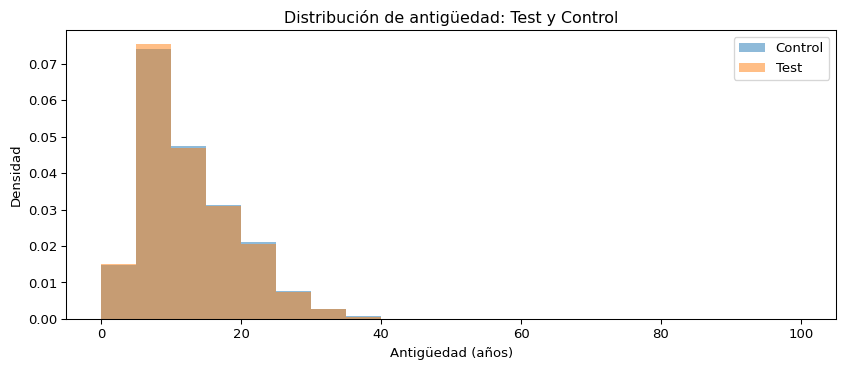

In [54]:
# Preparar una observación por cliente con antigüedad disponible
muestra_test = df_experimento.loc[df_experimento['Variation'] == 'Test', 'clnt_tenure_yr'].dropna()
muestra_control = df_experimento.loc[df_experimento['Variation'] == 'Control', 'clnt_tenure_yr'].dropna()

print('Clientes Test:', len(muestra_test))
print('Clientes Control:', len(muestra_control))
print('Media Test:', muestra_test.mean())
print('Media Control:', muestra_control.mean())
print('Diferencia Test - Control (años):', muestra_test.mean() - muestra_control.mean())

resultado = st.ttest_ind(muestra_test, muestra_control, equal_var=False, alternative='two-sided')
print('Estadístico t:', resultado.statistic)
print('P-valor:', resultado.pvalue)
if pd.isna(resultado.pvalue):
    print('Resultado no válido: revisar los datos antes de interpretar.')
elif resultado.pvalue < 0.05:
    print('Rechazamos H0: hay evidencia de una diferencia entre las medias.')
else:
    print('No rechazamos H0: no hay evidencia suficiente de una diferencia entre las medias.')

# Comparar las distribuciones con etiquetas correctas y los mismos intervalos
plt.figure(figsize=(9, 4))
plt.hist(muestra_control, bins=20, range=(0, 100), density=True, alpha=0.5, label='Control')
plt.hist(muestra_test, bins=20, range=(0, 100), density=True, alpha=0.5, label='Test')
plt.xlabel('Antigüedad (años)')
plt.ylabel('Densidad')
plt.title('Distribución de antigüedad: Test y Control')
plt.legend()
plt.tight_layout()
plt.show()

# Comprobar la sensibilidad a las inconsistencias de edad y antigüedad
perfil_sin_dudosos = df_experimento.loc[~casos_dudosos]
test_sin_dudosos = perfil_sin_dudosos.loc[perfil_sin_dudosos['Variation'] == 'Test', 'clnt_tenure_yr'].dropna()
control_sin_dudosos = perfil_sin_dudosos.loc[perfil_sin_dudosos['Variation'] == 'Control', 'clnt_tenure_yr'].dropna()
resultado_sensible = st.ttest_ind(test_sin_dudosos, control_sin_dudosos, equal_var=False, alternative='two-sided')
print('Sin casos dudosos:')
print('Clientes Test / Control:', len(test_sin_dudosos), len(control_sin_dudosos))
print('Diferencia de medias:', test_sin_dudosos.mean() - control_sin_dudosos.mean())
print('P-valor:', resultado_sensible.pvalue)
resultados_perfil_4 = {'p': float(resultado.pvalue), 'diferencia': float(muestra_test.mean() - muestra_control.mean()), 'p_sensibilidad': float(resultado_sensible.pvalue)}

### Interpretación del contraste 4

En el análisis principal de antigüedad, el p-valor es **0.0870**. Con un nivel de significación de 0,05, no rechazamos H₀: no hay evidencia suficiente de una diferencia de medias.

La diferencia de medias (Test menos Control) es de **-0.10 años**. Debemos valorar su magnitud, no solo el p-valor.

Al excluir los casos cuya antigüedad supera su edad, el p-valor es **0.0359** y cambia la decisión respecto al análisis principal; debemos presentar ambas versiones.

Este análisis evalúa la composición de los grupos. No demuestra aleatoriedad, ausencia de sesgos ni equivalencia. Tampoco mide si el nuevo diseño mejora la finalización.

## Contraste 5. Edad media de Test y Control

- H₀: la edad media es igual en Test y Control.
- H₁: la edad media es distinta.

Utilizamos un test t de Welch bilateral con significación de 0,05. Excluimos los nulos de edad antes de calcularlo: un p-valor `NaN` no permite tomar ninguna decisión estadística.

Este contraste compara la composición de los grupos. Es distinto del contraste 3, que estudia la asociación entre los tramos de edad y la finalización dentro de cada diseño.

Clientes Test: 26961
Clientes Control: 23526
Media Test: 47.16392196135158
Media Control: 47.498427271954434
Diferencia Test - Control (años): -0.33450531060285016
Estadístico t: -2.416068061200627
P-valor: 0.015692719461388675
Rechazamos H0: hay evidencia de una diferencia entre las medias.
Sin casos dudosos:
Clientes Test / Control: 26753 23363
Diferencia de medias: -0.32524404067368096
P-valor: 0.01859694220158058


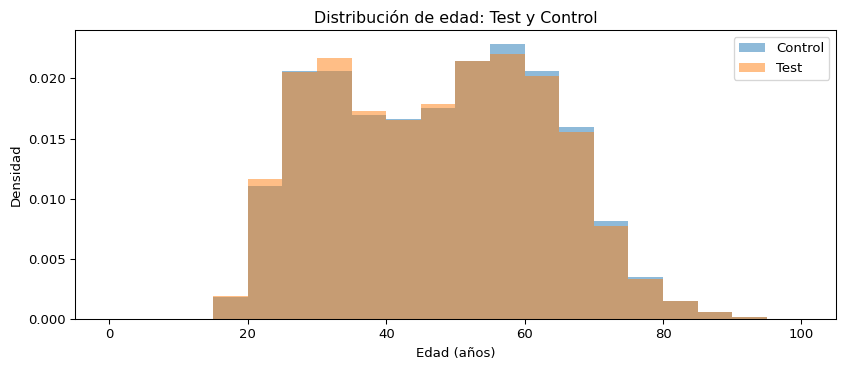

In [55]:
# Preparar una observación por cliente con edad disponible
muestra_test = df_experimento.loc[df_experimento['Variation'] == 'Test', 'clnt_age'].dropna()
muestra_control = df_experimento.loc[df_experimento['Variation'] == 'Control', 'clnt_age'].dropna()

print('Clientes Test:', len(muestra_test))
print('Clientes Control:', len(muestra_control))
print('Media Test:', muestra_test.mean())
print('Media Control:', muestra_control.mean())
print('Diferencia Test - Control (años):', muestra_test.mean() - muestra_control.mean())

resultado = st.ttest_ind(muestra_test, muestra_control, equal_var=False, alternative='two-sided')
print('Estadístico t:', resultado.statistic)
print('P-valor:', resultado.pvalue)
if pd.isna(resultado.pvalue):
    print('Resultado no válido: revisar los datos antes de interpretar.')
elif resultado.pvalue < 0.05:
    print('Rechazamos H0: hay evidencia de una diferencia entre las medias.')
else:
    print('No rechazamos H0: no hay evidencia suficiente de una diferencia entre las medias.')

# Comparar las distribuciones con etiquetas correctas y los mismos intervalos
plt.figure(figsize=(9, 4))
plt.hist(muestra_control, bins=20, range=(0, 100), density=True, alpha=0.5, label='Control')
plt.hist(muestra_test, bins=20, range=(0, 100), density=True, alpha=0.5, label='Test')
plt.xlabel('Edad (años)')
plt.ylabel('Densidad')
plt.title('Distribución de edad: Test y Control')
plt.legend()
plt.tight_layout()
plt.show()

# Comprobar la sensibilidad a las inconsistencias de edad y antigüedad
perfil_sin_dudosos = df_experimento.loc[~casos_dudosos]
test_sin_dudosos = perfil_sin_dudosos.loc[perfil_sin_dudosos['Variation'] == 'Test', 'clnt_age'].dropna()
control_sin_dudosos = perfil_sin_dudosos.loc[perfil_sin_dudosos['Variation'] == 'Control', 'clnt_age'].dropna()
resultado_sensible = st.ttest_ind(test_sin_dudosos, control_sin_dudosos, equal_var=False, alternative='two-sided')
print('Sin casos dudosos:')
print('Clientes Test / Control:', len(test_sin_dudosos), len(control_sin_dudosos))
print('Diferencia de medias:', test_sin_dudosos.mean() - control_sin_dudosos.mean())
print('P-valor:', resultado_sensible.pvalue)
resultados_perfil_5 = {'p': float(resultado.pvalue), 'diferencia': float(muestra_test.mean() - muestra_control.mean()), 'p_sensibilidad': float(resultado_sensible.pvalue)}

### Interpretación del contraste 5

En el análisis principal de edad, el p-valor es **0.0157**. Con un nivel de significación de 0,05, rechazamos H₀: hay evidencia de una diferencia de medias.

La diferencia de medias (Test menos Control) es de **-0.33 años**. Debemos valorar su magnitud, no solo el p-valor.

Al excluir los casos cuya antigüedad supera su edad, el p-valor es **0.0186** y también es inferior a 0,05.

Este análisis evalúa la composición de los grupos. No demuestra aleatoriedad, ausencia de sesgos ni equivalencia. Tampoco mide si el nuevo diseño mejora la finalización.

## Evaluación del experimento

### Diseño y composición de los grupos

Analizamos 50.500 participantes: 23.532 en Control (46,6 %) y 26.968 en Test (53,4 %). Cada cliente tiene una sola asignación y todos tienen actividad web registrada.

Los grupos tienen tamaños distintos. Esto no invalida por sí solo las comparaciones, pero necesitamos conocer la proporción prevista y el protocolo de asignación para evaluar el reparto. Las proporciones y medias permiten comparar grupos de distinto tamaño, aunque el tamaño influye en la precisión de las estimaciones.

Los perfiles descriptivos son parecidos. Los contrastes de edad y antigüedad añaden información sobre sus medias; no prueban por sí solos que la asignación fuera aleatoria o que no existan sesgos en otras variables. Una diferencia estadísticamente significativa puede ser pequeña en términos prácticos.

En edad, el contraste corregido da p = 0,0157: Test tiene una edad media 0,33 años menor (unos cuatro meses). La diferencia es significativa, pero pequeña; no contradice que las distribuciones sean visualmente similares.

En antigüedad, el resultado principal es p = 0,0870. Al excluir los casos dudosos pasa a p = 0,0359, por lo que la decisión estadística cambia. No presentamos este contraste como una conclusión robusta de igualdad: conservamos ambas versiones y señalamos la sensibilidad al criterio de inclusión.

### Calidad de datos y alcance de las métricas

Eliminamos 10.764 filas web exactamente duplicadas. Usamos cliente y visita para reconstruir los recorridos y excluimos los intervalos afectados por órdenes ambiguos al calcular tiempos y retrocesos.

Los 371 participantes cuya antigüedad supera su edad permanecen en el análisis principal. Presentamos comprobaciones sin ellos para valorar su influencia, sin inventar valores corregidos.

La finalización cuenta clientes; los tiempos cuentan intervalos observables; la tasa de retrocesos cuenta transiciones. No mezclamos estos denominadores. Las visitas repetidas no equivalen necesariamente a nuevos intentos fallidos.

Los retrocesos son una señal de comportamiento, no un registro de errores técnicos. El cálculo también incluye movimientos posteriores a `confirm` dentro de una visita. Los tiempos pueden incluir pausas y no miden actividad continua en pantalla.

### Duración

Los datos abarcan del 15 de marzo al 20 de junio de 2017. Este periodo y el volumen disponible permiten detectar una diferencia en la finalización general, pero no aportan evidencia suficiente para afirmar que la mejora real supera el 5 % relativo.

No hemos analizado la estabilidad semanal del efecto ni confirmado un seguimiento igual para todos los clientes. Cubrir unas 14 semanas no elimina automáticamente sesgos de calendario ni demuestra que el efecto se mantenga en el tiempo.

### Información adicional necesaria

- Protocolo de asignación y proporción prevista de Test y Control.
- Fecha de entrada y exposición de cada cliente al experimento.
- Dispositivo, navegador y origen del tráfico.
- Incidencias técnicas y motivos de interrupción o retroceso.
- Opiniones de usuarios y resultados posteriores a la confirmación.
- Costes del rediseño y beneficio asociado a las confirmaciones.

## Conclusiones

Test alcanza una finalización del **69,29 %**, frente al **65,59 %** de Control. La diferencia de **3,70 puntos porcentuales** es estadísticamente significativa.

La mejora relativa observada es del **5,65 %**, pero el contraste del umbral no permite afirmar que la mejora real supere el **5 % relativo**. Esto tampoco demuestra que el diseño no sea rentable.

La finalización en la primera visita mejora del **53,39 %** al **57,15 %**. Sin embargo, la tasa de retrocesos por transición aumenta del **8,66 %** al **11,50 %**, y el paso 1 presenta tiempos mayores en Test. Conviene investigar estos recorridos antes de recomendar un despliegue general.

La edad se asocia con la finalización en ambos grupos. Los mayores de 70 años muestran las menores tasas descriptivas. Esto no demuestra que la edad cause dificultades ni que el efecto del diseño sea distinto entre segmentos.

Los siguientes pasos son preparar las tablas para Tableau, validar las métricas del dashboard contra Python e integrar los resultados y limitaciones en la presentación. Los filtros demográficos deben recalcular las tasas con su denominador correspondiente.